# Лабораторна робота №5. Власне донавчання моделі
## Класифікація відгуків про настільні ігри на платформі MepleHub

### 1.1. Задача
MepleHub є платформою продажу настільних ігор. Класифікатор отримує українськомовний відгук про гру, магазин або обслуговування та повертає одну з п'яти категорій. Покупці можуть переглядати відгуки за категоріями, а модератор може перевіряти потенційно токсичні повідомлення. Негативна оцінка сама по собі не є підставою для видалення відгуку.


`positive`: схвальна оцінка товару або сервісу.

`negative`: невдоволення без конкретної пропозиції та без особистих образ.

`constructive`: конкретна пропозиція щодо покращення.

`neutral`: фактичний опис без оцінки.

`toxic`: особисті образи або приниження людей.

Для змішаних відгуків пріоритет має токсичність, потім конкретна пропозиція покращення; інакше визначається основна оцінка. Якщо оцінки немає, відгук нейтральний.

Звичайний промпт до генеративної моделі теж може розв'язувати задачу, але потребує повторного передавання інструкцій і не гарантує фіксованого формату. Класифікатор із новою головою повертає один із заданих класів без генерації тексту. RAG тут не потрібний, оскільки задача полягає у визначенні категорії самого відгуку, а не у пошуку зовнішньої інформації.

In [1]:
import random
import time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
assert torch.cuda.is_available(), "Потрібно підключити GPU в Google Colab"
torch.cuda.manual_seed_all(seed)
device = torch.device("cuda")
print(torch.cuda.get_device_name(0))
print(f"GPU: {torch.cuda.get_device_properties(0).total_memory / 2**30:.2f} GiB")

Tesla T4
GPU: 14.56 GiB


### 1.2. Модель і дані
Використовую базову модель [distilbert/distilbert-base-multilingual-cased](https://huggingface.co/distilbert/distilbert-base-multilingual-cased), ліцензія Apache 2.0. Вона має 6 шарів, приховану розмірність 768 і близько 134 млн параметрів, попередньо навчена на 104 мовах, зокрема українській. Це базова модель, а не модель типу Instruct. Вихідну голову для класифікації на п'ять класів ініціалізуємо заново.

Джерело даних: синтетичні українськомовні приклади, створені за допомогою генеративного ШІ спеціально для цієї лабораторної; це не справжні відгуки клієнтів MepleHub. Для створених прикладів застосовується CC0 1.0 у межах доступних прав (ліцензія самої моделі залишається Apache 2.0). Формат: текст, числовий клас, назва класу та позначення набору. Набори створено окремими списками, без автоматичного породження варіантів одного шаблону. Кожен набір збалансований за класами; тестові приклади не використовуються при навчанні та виборі найкращої епохи. Схожість стилю синтетичних відгуків залишається обмеженням експерименту.

In [2]:
data = {'positive': {'train': ['Грали всією родиною і чудово провели вечір.', 'Дуже захоплива гра, партії пролітають непомітно.', 'Якість карток приємно здивувала.', 'Діти в захваті від цієї настілки.', 'Гарний подарунок для компанії друзів.', 'Правила зрозумілі, розібралися за кілька хвилин.', 'Замовлення прийшло швидко, усе супер.', 'Ілюстрації неймовірно красиві.', 'Збалансована стратегія, хочеться зіграти ще.', 'Механіка торгівлі зробила партію цікавою.', 'Кубики якісні, приємно тримати в руках.', 'Вартує кожної гривні.', 'Нарешті знайшли гру, яка подобається всім.', 'Після першої партії одразу почали другу.', 'Доставка без проблем, коробка ціла.', 'Підтримка магазину допомогла вибрати чудову гру.', 'Дуже вдала українська локалізація.', 'Кожна партія виходить різною, не набридає.', 'Сподобалася взаємодія між гравцями.', 'Комплект перевершив мої очікування.', 'Чудове поєднання простих правил і глибокої стратегії.', 'Весела гра для вечірок, рекомендую.', 'Мініатюри зроблені дуже акуратно.', 'Покупкою повністю задоволений.', 'Малеча просить грати щодня.', 'Відмінна кооперативна гра, справді відчувається командна робота.', 'Зручний органайзер, усе лежить на своїх місцях.', 'Партія тримає інтригу до останнього ходу.', 'Продавець оперативно відповів, сервіс сподобався.', 'Гра виявилася набагато цікавішою, ніж на фото.', 'Класний спосіб провести час без телефонів.', 'Відчувається увага до деталей у кожному компоненті.', 'Гарно працює навіть удвох.', 'Знижка порадувала, покупка вдала.', 'Сюжет атмосферний, ніби поринаєш в інший світ.', 'Нарешті гра, у якій новачки мають шанс перемогти.', 'Гра зайшла навіть тим, хто не любить стратегії.', 'Приємне пакування і швидке оформлення.'],
 'validation': ['Вечір із цією грою був незабутнім.', 'Отримали багато задоволення від пошуку скарбів.', 'Поле міцне, друк чіткий, усе подобається.', 'Приємно, що гра не затягується.', 'Вдале доповнення до моєї колекції.', 'Сподобався незвичний механізм аукціону.', 'Магазин приємно вразив уважністю до замовлення.', 'Дуже вдало підібрані рівні складності.', 'Повертаємося до цієї гри кожних вихідних.', 'Чудова нагода зібрати друзів разом.'],
 'test': ['З дружиною не помітили, як минули три години за партією.', 'Ця коробка стала хітом нашого ігрового клубу.', 'Від механіки прихованих ролей отримав справжнє задоволення.', 'Оформлення карт персонажів просто розкішне.', 'Усі учасники захотіли реваншу, покупка вдала.', 'Менеджер уважно поставився до моїх побажань.', 'За таку ціну це справжня знахідка.', 'Навіть семирічний син легко освоїв гру і радів перемогам.', 'Я в захваті від того, як автори продумали економіку.', 'Давно не траплялася настілка з таким приємним темпом.']},
'negative': {'train': ['Гра виявилася дуже нудною.', 'Правила заплутані, грати не хочеться.', 'Картки почали стиратися після першої партії.', "Коробка приїхала пом'ятою.", 'За таку ціну очікував набагато більшого.', 'Партія тягнулася нескінченно.', 'Не сподобався баланс між персонажами.', 'Половину деталей не поклали в комплект.', 'Розчарований покупкою.', 'Гра не виправдала очікувань.', 'Доставка затрималася на тиждень.', 'Друк на полі розмитий.', 'Український переклад дуже слабкий.', 'Гравцям постійно доводиться довго чекати ходу.', 'Пластикові фігурки зламалися майже одразу.', 'Сюжет нецікавий і передбачуваний.', 'На двох гра зовсім не працює.', 'Отримав не той товар, який замовляв.', 'Служба підтримки так і не відповіла.', 'Інструкція не допомогла зрозуміти механіку.', 'Усі партії однакові, швидко набридло.', 'Ціна завищена, якість низька.', 'Поле надто тонке і вигинається.', 'Випадковість зводить усю стратегію нанівець.', 'Залишився незадоволений обслуговуванням.', 'Пакування було пошкоджене під час доставки.', 'Завдання в грі одноманітні.', 'Після двох партій поклали коробку на полицю.', 'Ігровий процес здається незавершеним.', 'Не раджу купувати це видання.', 'Занадто багато дрібних правил, це дратує.', 'Гра не підійшла нашій компанії.', 'Фарба з жетонів осипається.', 'Невдала покупка, шкода витрачених грошей.', 'Оплату підтвердили, а товар довго не відправляли.', 'Таймер працює нестабільно і псує партію.', 'Пазли погано стикуються між собою.', 'Нудна кінцівка зіпсувала враження.'],
 'validation': ['Матеріал мішечків виявився дуже дешевим.', 'Від гри очікували командної взаємодії, але її майже немає.', 'Замість нового примірника отримав коробку зі слідами використання.', 'Постійні нічиї роблять гру нецікавою.', 'Через довгу підготовку втратили бажання грати.', 'Враження від покупки неприємні.', 'Зображення персонажів не відповідають опису товару.', 'Велика коробка, а вмісту зовсім мало.', 'Відсутність нормальної відповіді від магазину засмутила.', 'Деякі карти мають однаковий ефект, механіка не захоплює.'],
 'test': ['Жетони ресурсів розшарувалися вже за один вечір.', 'У фіналі переможець визначається лише вдалим кидком, мені це не зайшло.', 'За ці гроші можна було придбати значно цікавішу настілку.', 'У правилах стільки суперечностей, що партію довелося припинити.', 'Замість приємної покупки отримав лише клопіт із поверненням.', 'Механізм підрахунку очок перетворює кінець гри на рутину.', 'Під час розкладання виявили, що бракує поля.', 'Від замовлення залишився гіркий осад.', 'Через дисбаланс один гравець перемагає майже завжди.', 'Насилу дограли до кінця, більше відкривати коробку не хочеться.']},
'constructive': {'train': ["Було б зручніше додати коротку пам'ятку правил кожному гравцю.", 'Пропоную збільшити шрифт на картках.', 'Варто додати окремий режим для двох гравців.', 'Хотілося б міцнішого картону для поля.', 'Раджу розділити компоненти по підписаних пакетах.', 'Можна скоротити підготовку до партії за допомогою органайзера.', 'Додайте більше прикладів ігрових ситуацій до інструкції.', 'Пропоную зробити окремий рівень складності для новачків.', 'Було б добре вказувати приблизну тривалість кожного сценарію.', 'Потрібно виправити кілька помилок у перекладі.', 'Рекомендую додати альтернативні кольори для жетонів.', 'Магазину варто оновлювати статус доставки частіше.', 'Можна зробити поле модульним для більшої різноманітності.', 'Хотів би бачити відеопояснення правил на сторінці товару.', 'Пропоную додати більше карт подій.', 'Для кращого балансу варто послабити стартову здатність мага.', 'Додайте захисну плівку на коробку перед відправкою.', 'Зручніше було б розмістити таблицю очок на звороті інструкції.', 'Варто передбачити місце для карт у протекторах.', 'Раджу вказувати точні розміри ігрового поля в описі.', 'Можна замінити частину випадкових ефектів на вибір гравця.', 'Було б добре мати цифрову версію правил.', 'Додайте фільтр за кількістю учасників у каталозі.', 'Пропоную зробити жетони різними не лише за кольором, а й за формою.', 'Для дитячого режиму можна спростити підрахунок очок.', 'Раджу покращити пакування мініатюр.', 'Хотілося б бачити перелік усіх компонентів на сайті.', 'Варто збільшити кількість завдань у кооперативному сценарії.', 'Можна запропонувати запасні кубики окремо.', 'Було б зручно отримувати сповіщення про появу гри в наявності.', 'Пропоную додати правила соло-режиму.', 'Варто замінити надто слизькі карти на матові.', 'Додайте можливість порівнювати ігри за складністю.', 'Першу партію можна полегшити готовим навчальним сценарієм.', 'Раджу обмежити тривалість ходу таймером.', 'Хотілося б окремої секції з уточненнями правил.', 'Варто перевіряти комплектність перед відправленням.', 'Можна покращити читабельність символів на темному фоні.'],
 'validation': ['Зробіть позначки на комірках органайзера, це пришвидшить складання.', 'Було б корисно додати варіант гри без вибування учасників.', 'Раджу дозволити вибір відділення доставки під час оформлення.', 'Щоб уникнути суперечок, поясніть порядок застосування бонусів.', 'Варто включити кілька запасних маркерів до набору.', 'Можна запропонувати готові набори ігор для різних вікових груп.', 'Для нічних партій краще використати контрастніші піктограми.', 'Додайте до опису фотографії компонентів у реальному масштабі.', 'Пропоную обмежити повторне використання сильних карт.', 'Спростити підрахунок ресурсів допомогли б окремі лічильники.'],
 'test': ['Якби на коробці був QR-код із поясненнями правил, новачкам було б простіше.', 'Для рівних шансів останньому гравцю можна давати додатковий ресурс.', 'Замість одного великого пакета краще використати окремі контейнери для фішок.', 'Зробіть можливість сортувати каталог за тривалістю партії.', 'Добре було б включити до гри приклад повністю зіграного раунду.', 'Раджу додати опис різниці між звичайною та подарунковою версіями.', 'Щоб зменшити час очікування, можна дозволити одночасно планувати ходи.', 'У майбутньому виданні хотілося б бачити двостороннє поле.', 'На сторінці товару варто розміщувати інформацію про сумісність доповнень.', 'Було б корисно додати окремі завдання для досвідчених учасників.']},
'neutral': {'train': ['У комплекті є 54 карти і шість кубиків.', 'Гра розрахована на двох-чотирьох учасників.', 'Замовив гру в понеділок.', 'На коробці зазначено вік від десяти років.', 'Партія триває приблизно 40 хвилин.', 'Правила надруковані українською мовою.', 'Розміри поля становлять 50 на 50 сантиметрів.', 'У каталозі є базова версія та доповнення.', "У кожного гравця на початку по п'ять монет.", 'Гра має три рівні складності.', 'Вага коробки становить один кілограм.', 'Товар отримав у відділенні пошти.', 'Картки поділені на чотири типи.', 'Учасники виконують ходи по черзі.', 'Переможець визначається за кількістю очок.', "У наборі є дерев'яні фішки.", 'Гра використовує механіку контролю територій.', 'Замовлення оформлено через сайт магазину.', 'Додаток продається окремо від основної гри.', 'У правилах описано два способи завершення партії.', 'Комплект містить поле, карти та інструкцію.', 'На сайті вказано ціну 850 гривень.', 'Перший хід робить наймолодший учасник.', "Сценарій складається з п'яти раундів.", 'Коробка має квадратну форму.', 'Гра доступна в українському виданні.', 'У партії використовуються жетони ресурсів.', 'Учасники можуть обмінюватися картами.', 'Оплату здійснив карткою.', 'Видавництво випустило гру торік.', 'У наборі чотири фігурки різних кольорів.', 'Зіграв одну партію з колегами.', 'Правила містять розділ для одиночної гри.', 'Відправлення надійшло у вівторок.', 'Кожна карта має числове значення.', 'Під час гри відкриваються нові локації.', 'Модель гри передбачає командний режим.', 'Для підрахунку балів є окремий блокнот.'],
 'validation': ['Перший сценарій займає шість раундів.', 'У каталозі зазначено виробника і країну видання.', 'Усі учасники отримують однаковий стартовий набір.', 'Гра містить 12 карт персонажів.', 'Доповнення використовує правила базового комплекту.', 'Після оформлення отримав номер замовлення.', 'Один із режимів передбачає гру на час.', 'У грі використовується шестигранний кубик.', 'Товщина карток становить приблизно пів міліметра.', 'Гравці починають із різних ділянок поля.'],
 'test': ['На звороті упаковки є перелік складових.', 'Для партії потрібен стіл розміром близько метра.', 'У сценарії про піратів учасники збирають золоті монети.', 'Замовлення забрав особисто з пункту видачі.', 'Видання містить правила двома мовами.', 'Учасники отримують випадкові ролі перед початком раунду.', 'У коробці лежать дві колоди по 30 карт.', 'Соло-режим передбачає окрему колоду супротивника.', 'Партія завершується після вичерпання запасу ресурсів.', 'На сторінці товару зазначено, що доповнення ще не надійшло.']},
'toxic': {'train': ['Тільки ідіот міг вигадати такі правила.', 'Автори цієї гри безмозкі.', 'Продавець тупий, нічого не розуміє.', 'Ті, хто це купує, повні дурні.', 'Розробник гри просто кретин.', 'Ваш менеджер неотесаний бовдур.', 'Видавець набрав одних ідіотів.', 'Автор інструкції тупоголовий.', 'Хто придумав ці карти, той йолоп.', 'Усі фанати цієї настілки дебіли.', 'Не хочу мати справу з такими придурками.', 'Дизайнер гри бездарний дурень.', 'Продавцю, ти взагалі маєш мізки?', 'Розробники нічого не тямлять, тупаки.', 'Той консультант справжній недоумок.', 'Тільки кретини можуть радити таку гру.', 'Ви в магазині всі бовдури.', 'Автори правил ідіоти, навіть читати не вміють.', 'Ваші працівники тупі як пробка.', 'Художник цих карт просто телепень.', 'Хто хвалить цю гру, той дурбецало.', 'З такими дурнями в підтримці нічого не вирішиш.', 'Власник магазину жалюгідний йолоп.', 'Автори, ви зовсім безголові.', "Кур'єр виявився повним придурком.", 'Менеджер, перестань тупити.', 'Геймдизайнеру бракує мізків, ідіот.', 'У вашій команді самі недолугі дурні.', 'Ти, продавцю, справжній кретин.', 'Гравець, який це порадив, безмозкий блазень.', 'Працівники складу тупоголові телепні.', 'Хто перекладав інструкцію, той бовдур.', 'Ви не магазин, а зборище придурків.', 'Покупці цієї гри просто йолопи.', 'Твоя порада, консультанте, показує, який ти дурень.', 'Автор цього доповнення цілковитий недоумок.', 'Модератор відгуків тупак, нічого не знає.', 'Ганьба вам, безмозкі розробники.'],
 'validation': ['Порадити це могла тільки людина без мізків.', 'Менеджер вашого магазину поводиться як тупий йолоп.', 'Хто створив сценарій, той повний недоумок.', 'Усі ваші консультанти неосвічені бовдури.', 'Авторе, ти просто придурок.', 'Тупий продавець не здатен навіть відповісти на питання.', 'Фанати цього видання поводяться як ідіоти.', 'Команда розробників складається з кретинів.', 'Ваш оператор справжній телепень.', 'Гравець, що написав позитивний відгук, просто дурень.'],
 'test': ['Хто відповідав за баланс, явно безмозкий йолоп.', 'Консультанте, ти тупий і нічого не знаєш про настілки.', 'Тільки придурок міг зібрати таку колоду.', 'У вашому видавництві працюють самі кретини.', 'Люди, які захищають це видання, повні бовдури.', 'Працівник, який пакував посилку, справжній ідіот.', 'Редактор правил виявився жалюгідним дурнем.', 'Підтримка набрана з тупоголових телепнів.', 'Художник персонажів просто недоумок.', 'Як можна слухати такого безмозкого оглядача?']}}

labels = list(data)
label_to_id = {name: i for i, name in enumerate(labels)}
label_names = {"positive": "Позитивний", "negative": "Негативний", "constructive": "Конструктивний", "neutral": "Нейтральний", "toxic": "Токсичний"}
rows = [{"text": text, "label": label_to_id[label], "category": label, "split": split} for label, parts in data.items() for split, texts in parts.items() for text in texts]
df = pd.DataFrame(rows)
assert not df["text"].str.strip().str.casefold().duplicated().any()
frames = {split: df[df["split"] == split].sample(frac=1, random_state=seed).reset_index(drop=True) for split in ("train", "validation", "test")}
print(f"Усього прикладів: {len(df)}")
display(pd.crosstab(df["category"], df["split"], margins=True))
display(frames["train"].groupby("category", sort=False).head(2)[["text", "category"]])

Усього прикладів: 290


split,test,train,validation,All
category,,,,
constructive,10,38,10,58
negative,10,38,10,58
neutral,10,38,10,58
positive,10,38,10,58
toxic,10,38,10,58
All,50,190,50,290


,text,category
0,"Автори, ви зовсім безголові.",toxic
1,"Ти, продавцю, справжній кретин.",toxic
2,Хотілося б окремої секції з уточненнями правил.,constructive
3,Після двох партій поклали коробку на полицю.,negative
4,Раджу покращити пакування мініатюр.,constructive
5,Підтримка магазину допомогла вибрати чудову гру.,positive
6,Механіка торгівлі зробила партію цікавою.,positive
8,Учасники можуть обмінюватися картами.,neutral
9,Вага коробки становить один кілограм.,neutral
17,Ігровий процес здається незавершеним.,negative


### 1.3. Модель до донавчання
Accuracy показує частку правильних відповідей, macro F1 усереднює F1 за всіма п'ятьма класами, тому враховує якість кожної категорії однаково. Базовий рівень полягає у передбаченні найчастішого класу тренувального набору; якщо частоти однакові, обираємо клас із найменшим ID. Додатково перевіряємо початкову модель з випадково ініціалізованою головою. Для порівняння до і після використовуємо ті самі десять прикладів і той самий тестовий набір.

In [3]:
model_id = "distilbert/distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=len(labels), id2label={i: name for i, name in enumerate(labels)}, label2id=label_to_id).to(device)

batch_size = 16
max_length = 96

class ReviewDataset(Dataset):
    def __init__(self, frame):
        self.encodings = tokenizer(frame["text"].tolist(), truncation=True, padding="max_length", max_length=max_length, return_tensors="pt")
        self.labels = torch.tensor(frame["label"].tolist(), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {**{key: value[i] for key, value in self.encodings.items()}, "labels": self.labels[i]}

generator = torch.Generator().manual_seed(seed)
loaders = {split: DataLoader(ReviewDataset(frame), batch_size=batch_size, shuffle=split == "train", generator=generator if split == "train" else None) for split, frame in frames.items()}

def evaluate(model, loader):
    model.eval()
    preds, targets = [], []
    loss_sum = 0.0
    with torch.no_grad():
        for batch in loader:
            batch = {key: value.to(device) for key, value in batch.items()}
            result = model(**batch)
            size = batch["labels"].size(0)
            loss_sum += result.loss.item() * size
            preds.extend(result.logits.argmax(dim=1).cpu().tolist())
            targets.extend(batch["labels"].cpu().tolist())
    return {"loss": loss_sum / len(targets), "accuracy": accuracy_score(targets, preds), "macro_f1": f1_score(targets, preds, labels=list(range(len(labels))), average="macro", zero_division=0), "preds": preds, "targets": targets}

counts = Counter(frames["train"]["label"])
majority = min(counts, key=lambda i: (-counts[i], i))
y_test = frames["test"]["label"].tolist()
majority_preds = [majority] * len(y_test)
baseline = {"accuracy": accuracy_score(y_test, majority_preds), "macro_f1": f1_score(y_test, majority_preds, labels=list(range(len(labels))), average="macro", zero_division=0)}
before = evaluate(model, loaders["test"])
assert before["targets"] == y_test
print(f"Базовий клас: {labels[majority]}")
display(pd.DataFrame([{"Модель": "Найчастіший клас", **baseline}, {"Модель": "DistilBERT до навчання", "accuracy": before["accuracy"], "macro_f1": before["macro_f1"]}]))
example_ids = frames["test"].groupby("label", sort=True).head(2).index.tolist()
examples = frames["test"].loc[example_ids, ["text", "category"]].copy()
examples["Базовий клас"] = [labels[majority_preds[i]] for i in example_ids]
examples["До навчання"] = [labels[before["preds"][i]] for i in example_ids]
display(examples)

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Базовий клас: positive


,Модель,accuracy,macro_f1
0,Найчастіший клас,0.2,0.066667
1,DistilBERT до навчання,0.2,0.066667


,text,category,Базовий клас,До навчання
0,"У правилах стільки суперечностей, що партію до...",negative,positive,neutral
1,"На сторінці товару зазначено, що доповнення ще...",neutral,positive,neutral
2,На звороті упаковки є перелік складових.,neutral,positive,neutral
3,"Працівник, який пакував посилку, справжній ідіот.",toxic,positive,neutral
4,Від замовлення залишився гіркий осад.,negative,positive,neutral
5,Художник персонажів просто недоумок.,toxic,positive,neutral
6,"Щоб зменшити час очікування, можна дозволити о...",constructive,positive,neutral
7,Раджу додати опис різниці між звичайною та под...,constructive,positive,neutral
11,"Усі учасники захотіли реваншу, покупка вдала.",positive,positive,neutral
13,"Я в захваті від того, як автори продумали екон...",positive,positive,neutral


### 1.4. Донавчання
Використовую класичне донавчання з новою класифікаційною головою: оновлюються всі параметри DistilBERT та голови. Learning rate 3e-5, оптимізатор AdamW, batch size 16, максимум 6 епох, довжина послідовності до 96 токенів. Невеликий learning rate зменшує ризик різкої зміни попередньо навчених ваг; шість епох дозволяють простежити динаміку похибки на малому наборі. Після кожної епохи оцінюю validation loss та зберігаю найкращий стан за цією метрикою у RAM. Тестовий набір не використовується для вибору стану моделі. Для вимірювання часу включено тренування та валідацію, пікову пам'ять вимірюю через PyTorch.

In [4]:
epochs = 6
learning_rate = 3e-5
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
history = []
best_loss = float("inf")
best_epoch = None
best_state = None
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats(device)
started = time.perf_counter()

for epoch in range(1, epochs + 1):
    model.train()
    train_loss_sum = 0.0
    for batch in loaders["train"]:
        batch = {key: value.to(device) for key, value in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        result = model(**batch)
        result.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss_sum += result.loss.item() * batch["labels"].size(0)
    val = evaluate(model, loaders["validation"])
    row = {"epoch": epoch, "training_loss": train_loss_sum / len(frames["train"]), "validation_loss": val["loss"], "validation_accuracy": val["accuracy"], "validation_macro_f1": val["macro_f1"]}
    history.append(row)
    if val["loss"] < best_loss:
        best_loss = val["loss"]
        best_epoch = epoch
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    print(f"Епоха {epoch}: train loss={row['training_loss']:.4f}, val loss={val['loss']:.4f}, val accuracy={val['accuracy']:.4f}, val macro F1={val['macro_f1']:.4f}")

torch.cuda.synchronize()
training_seconds = time.perf_counter() - started
peak_memory = torch.cuda.max_memory_allocated(device) / 2**30
model.load_state_dict(best_state)
del best_state, optimizer
history_df = pd.DataFrame(history)
display(history_df)
print(f"Час навчання та валідації: {training_seconds:.2f} с")
print(f"Пікова виділена пам'ять GPU: {peak_memory:.2f} GiB")
print(f"Вибрана епоха: {best_epoch}")

Епоха 1: train loss=1.5936, val loss=1.5037, val accuracy=0.6000, val macro F1=0.5332
Епоха 2: train loss=1.3717, val loss=1.1984, val accuracy=0.6600, val macro F1=0.5849
Епоха 3: train loss=0.9738, val loss=0.9061, val accuracy=0.6800, val macro F1=0.6480
Епоха 4: train loss=0.6274, val loss=0.7899, val accuracy=0.6800, val macro F1=0.6422
Епоха 5: train loss=0.3906, val loss=0.6656, val accuracy=0.7600, val macro F1=0.7472
Епоха 6: train loss=0.1928, val loss=0.6964, val accuracy=0.7400, val macro F1=0.7165


,epoch,training_loss,validation_loss,validation_accuracy,validation_macro_f1
0,1,1.593627,1.503718,0.60,0.533183
1,2,1.371675,1.198386,0.66,0.584928
2,3,0.973829,0.906118,0.68,0.647959
3,4,0.627370,0.789902,0.68,0.642167
4,5,0.390569,0.665577,0.76,0.747228
5,6,0.192752,0.696401,0.74,0.716507


Час навчання та валідації: 18.51 с
Пікова виділена пам'ять GPU: 2.54 GiB
Вибрана епоха: 5


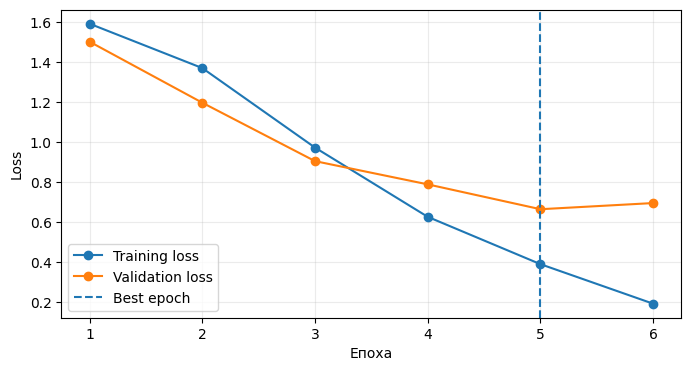

Після епохи 5 навчальна похибка зменшилася, а валідаційна зросла. Це ознака можливого перенавчання; відновлено стан з мінімальним validation loss.


In [5]:
plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["training_loss"], marker="o", label="Training loss")
plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation loss")
plt.axvline(best_epoch, linestyle="--", label="Best epoch")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(alpha=0.25)
plt.show()

last = history[-1]
chosen = history[best_epoch - 1]
if best_epoch < epochs and last["training_loss"] < chosen["training_loss"] and last["validation_loss"] > chosen["validation_loss"]:
    overfit_text = f"Після епохи {best_epoch} навчальна похибка зменшилася, а валідаційна зросла. Це ознака можливого перенавчання; відновлено стан з мінімальним validation loss."
elif best_epoch < epochs:
    overfit_text = f"Валідаційна похибка була найменшою на епосі {best_epoch}. Відновлено цей стан; за самою динамікою похибок немає достатніх підстав однозначно стверджувати перенавчання."
else:
    overfit_text = "Мінімальна validation loss отримана на останній епосі. За цим критерієм явного погіршення наприкінці навчання не зафіксовано."
print(overfit_text)

### 1.5. Порівняння
Порівнюю три варіанти на тому самому тестовому наборі. Аналізую також матрицю помилок та окремі помилкові відгуки. Перевірка загальних генеративних запитів не потрібна, оскільки використовую класифікатор, а не генеративну LLM.

,Модель,accuracy,macro_f1
0,Найчастіший клас,0.2,0.066667
1,DistilBERT до навчання,0.2,0.066667
2,DistilBERT після навчання,0.7,0.680262


,text,category,Базовий клас,До навчання,Після навчання
0,"У правилах стільки суперечностей, що партію до...",negative,positive,neutral,positive
1,"На сторінці товару зазначено, що доповнення ще...",neutral,positive,neutral,positive
2,На звороті упаковки є перелік складових.,neutral,positive,neutral,neutral
3,"Працівник, який пакував посилку, справжній ідіот.",toxic,positive,neutral,toxic
4,Від замовлення залишився гіркий осад.,negative,positive,neutral,negative
5,Художник персонажів просто недоумок.,toxic,positive,neutral,toxic
6,"Щоб зменшити час очікування, можна дозволити о...",constructive,positive,neutral,constructive
7,Раджу додати опис різниці між звичайною та под...,constructive,positive,neutral,constructive
11,"Усі учасники захотіли реваншу, покупка вдала.",positive,positive,neutral,positive
13,"Я в захваті від того, як автори продумали екон...",positive,positive,neutral,toxic


              precision    recall  f1-score   support

    positive       0.43      0.60      0.50        10
    negative       0.50      0.20      0.29        10
constructive       0.77      1.00      0.87        10
     neutral       1.00      0.80      0.89        10
       toxic       0.82      0.90      0.86        10

    accuracy                           0.70        50
   macro avg       0.70      0.70      0.68        50
weighted avg       0.70      0.70      0.68        50



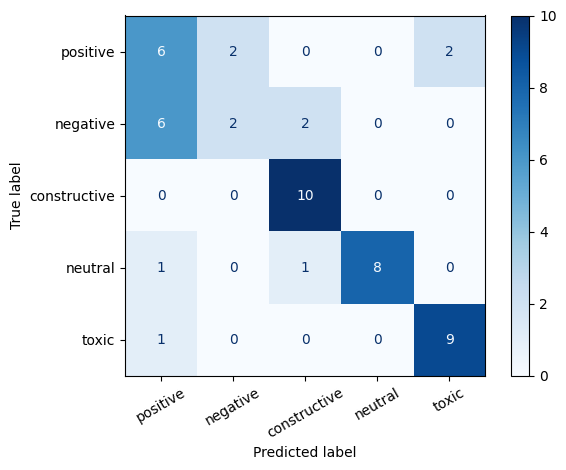

Помилки: 15 з 50


,text,category,prediction
0,"У правилах стільки суперечностей, що партію до...",negative,positive
1,"На сторінці товару зазначено, що доповнення ще...",neutral,positive
9,"Насилу дограли до кінця, більше відкривати кор...",negative,positive
10,За ці гроші можна було придбати значно цікавіш...,negative,constructive
13,"Я в захваті від того, як автори продумали екон...",positive,toxic
18,Підтримка набрана з тупоголових телепнів.,toxic,positive
19,Механізм підрахунку очок перетворює кінець гри...,negative,constructive
24,Для партії потрібен стіл розміром близько метра.,neutral,constructive
25,"З дружиною не помітили, як минули три години з...",positive,negative
29,Менеджер уважно поставився до моїх побажань.,positive,toxic


Найчастіше серед помилок: Негативний → Позитивний (6).


In [6]:
after = evaluate(model, loaders["test"])
assert after["targets"] == before["targets"] == y_test
comparison = pd.DataFrame([
    {"Модель": "Найчастіший клас", **baseline},
    {"Модель": "DistilBERT до навчання", "accuracy": before["accuracy"], "macro_f1": before["macro_f1"]},
    {"Модель": "DistilBERT після навчання", "accuracy": after["accuracy"], "macro_f1": after["macro_f1"]}
])
display(comparison)
examples["Після навчання"] = [labels[after["preds"][i]] for i in example_ids]
display(examples)
print(classification_report(y_test, after["preds"], labels=list(range(len(labels))), target_names=labels, zero_division=0))
cm = confusion_matrix(y_test, after["preds"], labels=list(range(len(labels))))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(xticks_rotation=30, cmap="Blues")
plt.tight_layout()
plt.show()
results = frames["test"][["text", "category"]].copy()
results["prediction"] = [labels[i] for i in after["preds"]]
errors = results[results["category"] != results["prediction"]].copy()
print(f"Помилки: {len(errors)} з {len(results)}")
display(errors)
confusions = Counter(zip(errors["category"], errors["prediction"]))
if confusions:
    (true_label, predicted_label), amount = confusions.most_common(1)[0]
    error_summary = f"Найчастіше серед помилок: {label_names[true_label]} → {label_names[predicted_label]} ({amount})."
else:
    error_summary = "На цьому невеликому синтетичному тестовому наборі помилок не виявлено. Це не гарантує такої самої якості на реальних відгуках."
print(error_summary)

### Додаткові приклади для перевірки
Окремі відгуки не належать до навчального, валідаційного чи тестового набору. Тут перевіряю, як модель реагує на змішані оцінки, іронію, непрямі пропозиції та образи. Ці приклади не впливають на основні метрики.

In [7]:
extra = [
    ("Гра чудова, але додайте, будь ласка, правила для двох.", "constructive"),
    ("Ну так, три години читати правила — саме про це я мріяв.", "negative"),
    ("Упаковка містить 80 карт і чотири планшети.", "neutral"),
    ("Гра цікава, але продавець справжній ідіот.", "toxic"),
    ("Не очікував, що настільки сподобається гра з кубиками.", "positive"),
    ("Якби у магазині були фото внутрішніх компонентів, вибирати було б легше.", "constructive")
]
assert not set(text for text, _ in extra) & set(df["text"])
model.eval()
with torch.no_grad():
    inputs = tokenizer([text for text, _ in extra], padding=True, truncation=True, max_length=max_length, return_tensors="pt").to(device)
    extra_preds = model(**inputs).logits.argmax(dim=1).cpu().tolist()
extra_df = pd.DataFrame({"text": [text for text, _ in extra], "expected": [label for _, label in extra], "prediction": [labels[i] for i in extra_preds]})
display(extra_df)
print(f"Правильних додаткових прикладів: {(extra_df.expected == extra_df.prediction).sum()} з {len(extra_df)}")

,text,expected,prediction
0,"Гра чудова, але додайте, будь ласка, правила д...",constructive,toxic
1,"Ну так, три години читати правила — саме про ц...",negative,toxic
2,Упаковка містить 80 карт і чотири планшети.,neutral,neutral
3,"Гра цікава, але продавець справжній ідіот.",toxic,toxic
4,"Не очікував, що настільки сподобається гра з к...",positive,negative
5,Якби у магазині були фото внутрішніх компонент...,constructive,constructive


Правильних додаткових прикладів: 3 з 6


### 1.6. Мій звіт
Підсумковий звіт нижче формується з фактичних результатів виконання комірок. Причини окремих помилок є можливими поясненнями, а не доказом внутрішнього механізму моделі.

In [8]:
gain = after["accuracy"] - before["accuracy"]
f1_gain = after["macro_f1"] - before["macro_f1"]
if after["accuracy"] > max(before["accuracy"], baseline["accuracy"]) and after["macro_f1"] > max(before["macro_f1"], baseline["macro_f1"]):
    conclusion = "Донавчання покращило обидві метрики порівняно з обома базовими рівнями."
else:
    conclusion = "Донавчання не перевершило обидва базові рівні за всіма метриками; необхідно перевірити дані та гіперпараметри."
error_lines = []
for _, item in errors.head(5).iterrows():
    pair = {item["category"], item["prediction"]}
    if pair == {"negative", "constructive"}:
        reason = "можлива причина: схожі формулювання про недоліки; модель не відокремила пропозицію від скарги"
    elif "neutral" in pair:
        reason = "можлива причина: неявна оцінка або недостатньо виразні оцінні слова"
    elif "toxic" in pair:
        reason = "можлива причина: модель не відокремила образу людини від оцінки товару або сервісу"
    else:
        reason = "можлива причина: недостатня різноманітність навчальних прикладів для такого формулювання"
    error_lines.append(f'«{item["text"]}»: очікувалось {label_names[item["category"]]}, отримано {label_names[item["prediction"]]}; {reason}.')
error_details = "\n\n".join(error_lines) if error_lines else "Помилкових тестових прикладів немає; додаткова перевірка допомагає оцінити складніші формулювання."
extra_correct = int((extra_df.expected == extra_df.prediction).sum())
report = f"""
**Задача і чому потрібне донавчання:** Класифікація українськомовних відгуків про настільні ігри та сервіс MepleHub за п’ятьма категоріями. Донавчання дає класифікатор із фіксованим виходом без повторного введення промпту; RAG не потрібний, бо зовнішні дані не використовуються.

**Модель і дані:** Багатомовний DistilBERT (134 млн параметрів, Apache 2.0), синтетичні приклади (CC0 1.0 у межах доступних прав), {len(df)} відгуків: train: {len(frames['train'])}, validation: {len(frames['validation'])}, test: {len(frames['test'])}. Усі класи збалансовані.

**Метрика й результат до донавчання:** Accuracy і macro F1. Найчастіший клас: {baseline['accuracy']:.2%}, macro F1 {baseline['macro_f1']:.4f}; початкова модель: {before['accuracy']:.2%}, macro F1 {before['macro_f1']:.4f}.

**Метод донавчання й гіперпараметри:** Класичне донавчання з новою головою, AdamW, learning rate {learning_rate}, batch size {batch_size}, {epochs} епох. Час {training_seconds:.2f} с, пікова виділена пам'ять GPU {peak_memory:.2f} GiB. Вибрана епоха {best_epoch}. {overfit_text}

**Результат після донавчання:** Accuracy {after['accuracy']:.2%}, macro F1 {after['macro_f1']:.4f}. Зміна відносно початкової моделі: {gain * 100:+.2f} відсоткового пункту accuracy, {f1_gain:+.4f} macro F1.

**Аналіз помилок:** {error_summary} На додаткових складніших прикладах правильно класифіковано {extra_correct} з {len(extra_df)}.

{error_details}

**Висновок:** {conclusion} Невеликий синтетичний набір не відображає всі способи написання реальних відгуків. Перед інтеграцією в MepleHub потрібно оцінити модель на незалежних розмічених реальних відгуках. Токсичні повідомлення варто передавати на перевірку модератору, а не автоматично видаляти.
"""
display(Markdown(report))


**Задача і чому потрібне донавчання:** Класифікація українськомовних відгуків про настільні ігри та сервіс MepleHub за п’ятьма категоріями. Донавчання дає класифікатор із фіксованим виходом без повторного введення промпту; RAG не потрібний, бо зовнішні дані не використовуються.

**Модель і дані:** Багатомовний DistilBERT (134 млн параметрів, Apache 2.0), синтетичні приклади (CC0 1.0 у межах доступних прав), 290 відгуків: train: 190, validation: 50, test: 50. Усі класи збалансовані.

**Метрика й результат до донавчання:** Accuracy і macro F1. Найчастіший клас: 20.00%, macro F1 0.0667; початкова модель: 20.00%, macro F1 0.0667.

**Метод донавчання й гіперпараметри:** Класичне донавчання з новою головою, AdamW, learning rate 3e-05, batch size 16, 6 епох. Час 18.51 с, пікова виділена пам'ять GPU 2.54 GiB. Вибрана епоха 5. Після епохи 5 навчальна похибка зменшилася, а валідаційна зросла. Це ознака можливого перенавчання; відновлено стан з мінімальним validation loss.

**Результат після донавчання:** Accuracy 70.00%, macro F1 0.6803. Зміна відносно початкової моделі: +50.00 відсоткового пункту accuracy, +0.6136 macro F1.

**Аналіз помилок:** Найчастіше серед помилок: Негативний → Позитивний (6). На додаткових складніших прикладах правильно класифіковано 3 з 6.

«У правилах стільки суперечностей, що партію довелося припинити.»: очікувалось Негативний, отримано Позитивний; можлива причина: недостатня різноманітність навчальних прикладів для такого формулювання.

«На сторінці товару зазначено, що доповнення ще не надійшло.»: очікувалось Нейтральний, отримано Позитивний; можлива причина: неявна оцінка або недостатньо виразні оцінні слова.

«Насилу дограли до кінця, більше відкривати коробку не хочеться.»: очікувалось Негативний, отримано Позитивний; можлива причина: недостатня різноманітність навчальних прикладів для такого формулювання.

«За ці гроші можна було придбати значно цікавішу настілку.»: очікувалось Негативний, отримано Конструктивний; можлива причина: схожі формулювання про недоліки; модель не відокремила пропозицію від скарги.

«Я в захваті від того, як автори продумали економіку.»: очікувалось Позитивний, отримано Токсичний; можлива причина: модель не відокремила образу людини від оцінки товару або сервісу.

**Висновок:** Донавчання покращило обидві метрики порівняно з обома базовими рівнями. Невеликий синтетичний набір не відображає всі способи написання реальних відгуків. Перед інтеграцією в MepleHub потрібно оцінити модель на незалежних розмічених реальних відгуках. Токсичні повідомлення варто передавати на перевірку модератору, а не автоматично видаляти.
